In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_excel('eda.xlsm')

In [9]:
df.head()

,Jersey No,Player,Matches,Inns,Not Out,Runs,Highest Score,Avg,Balls faced,Strike rate,100,50,4s,6s
0,1,KL Rahul,14,14,2,670,132*,55.83,518,129.34,1,5,58,23
1,2,Shikhar Dhawan,17,17,3,618,106*,44.14,427,144.73,2,4,67,12
2,3,David Warner,16,16,2,548,85*,39.14,407,134.64,0,4,52,14
3,4,Shreyas Iyer,17,17,2,519,88*,34.60,421,123.27,0,3,40,16
4,5,Ishan Kishan,14,13,4,516,99,57.33,354,145.76,0,4,36,30


In [10]:
df.columns

Index([    'Jersey No',        'Player',       'Matches',          'Inns',
             'Not Out',          'Runs', 'Highest Score',           'Avg',
         'Balls faced',   'Strike rate',             100,              50,
                  '4s',            '6s'],
      dtype='object')

In [11]:
df.dtypes

Jersey No          int64
Player            object
Matches            int64
Inns               int64
Not Out            int64
Runs               int64
Highest Score     object
Avg              float64
Balls faced        int64
Strike rate      float64
100                int64
50                 int64
4s                 int64
6s                 int64
dtype: object

In [12]:
df.shape

(133, 14)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 133 entries, 0 to 132
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Jersey No      133 non-null    int64  
 1   Player         133 non-null    object 
 2   Matches        133 non-null    int64  
 3   Inns           133 non-null    int64  
 4   Not Out        133 non-null    int64  
 5   Runs           133 non-null    int64  
 6   Highest Score  133 non-null    object 
 7   Avg            133 non-null    float64
 8   Balls faced    133 non-null    int64  
 9   Strike rate    133 non-null    float64
 10  100            133 non-null    int64  
 11  50             133 non-null    int64  
 12  4s             133 non-null    int64  
 13  6s             133 non-null    int64  
dtypes: float64(2), int64(10), object(2)
memory usage: 14.7+ KB


In [29]:
df.isnull().sum()

Jersey No        0
Player           0
Matches          0
Inns             0
Not Out          0
Runs             0
Highest Score    0
Avg              0
Balls faced      0
Strike rate      0
100              0
50               0
4s               0
6s               0
dtype: int64

In [30]:
df.duplicated().sum()

np.int64(0)

# Q1. What is the maximum number of matches played by an individual player in a season? Print the player name along with the number of matched played.

In [31]:
df.iloc[df['Matches'].idxmax()][['Player','Matches']]

Player     Shikhar Dhawan
Matches                17
Name: 1, dtype: object

In [ ]:
df.loc[df['Matches'].idxmax(), ['Player', 'Matches']]

In [ ]:
df.loc[df['Matches'] == df['Matches'].max(), ['Player', 'Matches']]

In [32]:
df.loc[df['Matches']==df['Matches'].max()][['Player','Matches']].reset_index(drop=1)

,Player,Matches
0,Shikhar Dhawan,17
1,Shreyas Iyer,17
2,Marcus Stoinis,17
3,Kagiso Rabada,17


# Q2. Top 2 players with maximum Average who have scored atleast 2 half centuries ?

In [33]:
df[df[50]>=2].sort_values(by='Avg',ascending=False)[['Player','Avg',50]].reset_index(drop=True).head(2)

,Player,Avg,50
0,Ishan Kishan,57.33,4
1,KL Rahul,55.83,5


# Q3. Create 2 new columns based on Player name. First column will have first name and second column will have last name. Eg: for the player Shikhar Dhawan, Shikhar will be the first name and Dhawan will be the last name.

In [34]:
df[['First Name','Last Name']]=df['Player'].str.split(n=1,expand=True)

In [35]:
df.head(3)

,Jersey No,Player,Matches,Inns,Not Out,Runs,Highest Score,Avg,Balls faced,Strike rate,100,50,4s,6s,First Name,Last Name
0,1,KL Rahul,14,14,2,670,132*,55.83,518,129.34,1,5,58,23,KL,Rahul
1,2,Shikhar Dhawan,17,17,3,618,106*,44.14,427,144.73,2,4,67,12,Shikhar,Dhawan
2,3,David Warner,16,16,2,548,85*,39.14,407,134.64,0,4,52,14,David,Warner


# Q4. Create a new column (Cleaned_Highest_score) based on Highest score variable. Remove the Asterik(*) mark and convert the data type into INT

In [36]:
df['Clean']=df['Highest Score'].astype(str).str.replace('*','',regex=False).astype(int)

In [37]:
df.head(3)

,Jersey No,Player,Matches,Inns,Not Out,Runs,Highest Score,Avg,Balls faced,Strike rate,100,50,4s,6s,First Name,Last Name,Clean
0,1,KL Rahul,14,14,2,670,132*,55.83,518,129.34,1,5,58,23,KL,Rahul,132
1,2,Shikhar Dhawan,17,17,3,618,106*,44.14,427,144.73,2,4,67,12,Shikhar,Dhawan,106
2,3,David Warner,16,16,2,548,85*,39.14,407,134.64,0,4,52,14,David,Warner,85


# Q5. Print the total number of centuries scored in the entire season

In [38]:
print(f'The Total No of Century Scored in the season is {df[100].sum()}')

The Total No of Century Scored in the season is 5


# Q6. Print all the player names whose strike rate is less than the average strike rate of all players in entire season. Print the player name, his strike rate and average strike rate.

In [39]:
avg = df['Strike rate'].mean()
print(avg)

107.36473684210526


In [40]:
df[df['Strike rate']<avg][['Player','Strike rate']].reset_index(drop=True)

,Player,Strike rate
0,Ajinkya Rahane,105.60
1,Glenn Maxwell,101.88
2,Vijay Shankar,101.04
3,Josh Philippe,101.29
4,Gurkeerat Singh,88.75
5,Kedar Jadhav,93.93
6,Yashasvi Jaiswal,90.90
7,Shreyas Gopal,94.87
8,Murali Vijay,74.41
9,Chris Jordan,93.54


# Q7. Please check the correlation between the features and create a heat map.

In [41]:
df_num = df.select_dtypes(include=['number'])
df_num.head(3)
#creating the df_num for a correlation matrix

,Jersey No,Matches,Inns,Not Out,Runs,Avg,Balls faced,Strike rate,100,50,4s,6s,Clean
0,1,14,14,2,670,55.83,518,129.34,1,5,58,23,132
1,2,17,17,3,618,44.14,427,144.73,2,4,67,12,106
2,3,16,16,2,548,39.14,407,134.64,0,4,52,14,85


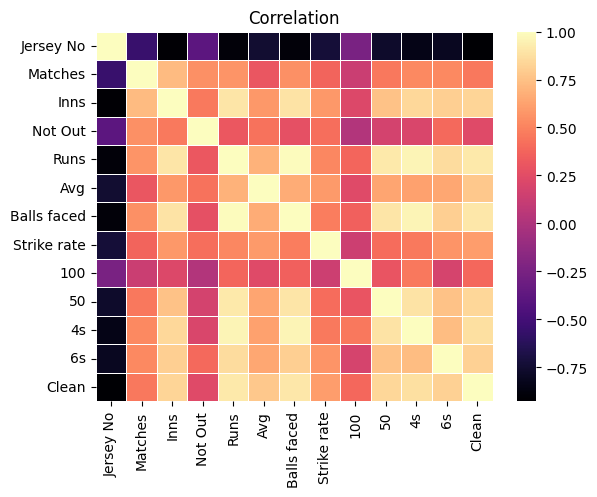

In [42]:
sns.heatmap(df_num.corr(),annot=False,cmap='magma', linewidths=0.5)
plt.title('Correlation')
plt.show()

# Q8. Check the list of players who has an average greater than 50 as well strike rate above 120. Print player name, average and strike rate

In [43]:
df[(df['Avg']>50) & (df['Strike rate']>120)][['Player','Avg','Strike rate']].sort_values(by='Avg',ascending=0).reset_index(drop=True)

,Player,Avg,Strike rate
0,Deepak Hooda,101.00,142.25
1,Tom Curran,83.00,133.87
2,Wriddhiman Saha,71.33,139.86
3,Ishan Kishan,57.33,145.76
4,KL Rahul,55.83,129.34
5,Kieron Pollard,53.60,191.42
6,Ruturaj Gaikwad,51.00,120.71


# Q9. Please check the list of players who has an average greater than 40 and balls faced above 100. Print player name, average and balls faced

In [44]:
df[(df['Avg']>40)  & (df['Balls faced']>100)][['Player','Avg','Balls faced']].sort_values(by='Avg',ascending=0).reset_index(drop=True)

,Player,Avg,Balls faced
0,Wriddhiman Saha,71.33,153
1,Ishan Kishan,57.33,354
2,KL Rahul,55.83,518
3,Kieron Pollard,53.60,140
4,Ruturaj Gaikwad,51.00,169
5,Ravindra Jadeja,46.40,135
6,ABD Villiers,45.40,286
7,Kane Williamson,45.28,237
8,Shikhar Dhawan,44.14,427
9,Rahul Tewatia,42.50,183


# Q10. Players who scored atleast one century in this season. Create visualization

In [45]:
cdf= df[df[100]>0].sort_values(by =100,ascending=False)

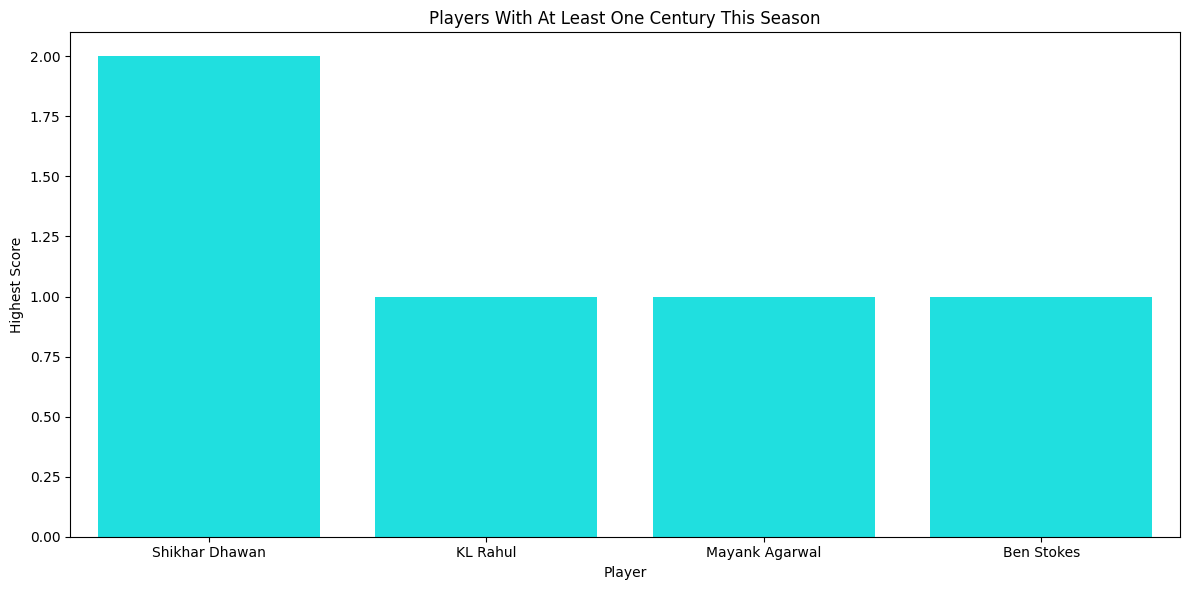

In [46]:
plt.figure(figsize=(12, 6))
sns.barplot(data=cdf, x='Player', y=100 ,color='cyan')

plt.title('Players With At Least One Century This Season')
plt.xlabel('Player')
plt.ylabel('Highest Score')
plt.tight_layout()
plt.show()

# Q11. Players who scored atleast 4 half centuries in this season.

In [47]:
df[df[50]>=4][['Player',50]].sort_values(by=50,ascending=0)

,Player,50
0,KL Rahul,5
9,ABD Villiers,5
7,Devdutt Padikkal,5
1,Shikhar Dhawan,4
2,David Warner,4
5,Quinton Kock,4
4,Ishan Kishan,4
6,Suryakumar Yadav,4
10,Faf Duplessis,4


# Q12. Check the list of players who hit more than 45 boundaries and more than 10 sixes in this season.

In [48]:
df[((df['4s']+df['6s'])>45)&(df['6s']>10)][['Player','4s','6s']]

,Player,4s,6s
0,KL Rahul,58,23
1,Shikhar Dhawan,67,12
2,David Warner,52,14
3,Shreyas Iyer,40,16
4,Ishan Kishan,36,30
5,Quinton Kock,46,22
6,Suryakumar Yadav,61,11
9,ABD Villiers,33,23
10,Faf Duplessis,42,14
12,Manish Pandey,35,18


# Q13. Plot a histogram of number of matches played in a season by players.

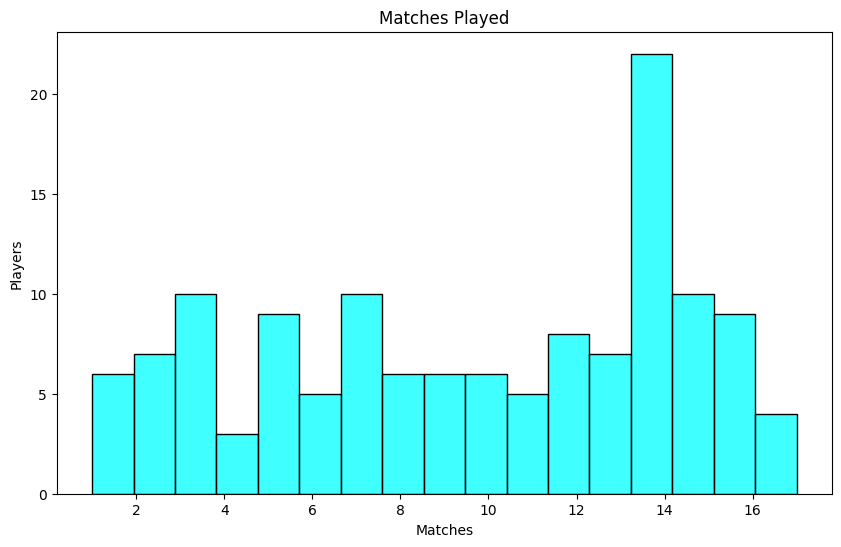

In [49]:
plt.figure(figsize=(10,6))
sns.histplot(df['Matches'],bins=17,color='cyan')

plt.title('Matches Played')
plt.xlabel('Matches')
plt.ylabel('Players')
plt.show()

# Q14. Plot the histogram of balls faced by players.

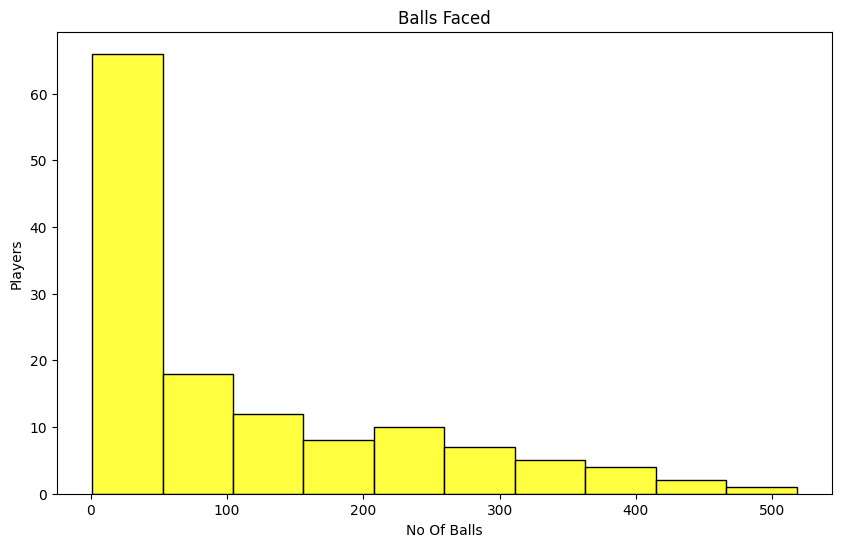

In [50]:
plt.figure(figsize=(10,6))
sns.histplot(df['Balls faced'],bins=10,color='yellow')



plt.title('Balls Faced')
plt.xlabel('No Of Balls')
plt.ylabel('Players')
plt.show()

# Q15. Top 10 players with most runs in a season

In [51]:
df[['Player','Runs']].sort_values(by='Runs',ascending=False).head(10)

,Player,Runs
0,KL Rahul,670
1,Shikhar Dhawan,618
2,David Warner,548
3,Shreyas Iyer,519
4,Ishan Kishan,516
5,Quinton Kock,503
6,Suryakumar Yadav,480
7,Devdutt Padikkal,473
8,Virat Kohli,466
9,ABD Villiers,454


# Q16 Print the players who played the match but didn't get the batting.

In [52]:
df['Not Batted'] = df['Matches']-df['Inns']
df[df['Not Batted']!=0][['Player','Matches','Not Batted']].sort_values(by='Not Batted',ascending=False).reset_index(drop=1)

,Player,Matches,Not Batted
0,Jasprit Bumrah,15,14
1,Trent Boult,15,14
2,Rahul Chahar,15,14
3,Yuzvendra Chahal,15,13
4,T Natarajan,16,13
...,...,...,...
82,Abhishek Sharma,8,1
83,Shahbaz Ahmed,2,1
84,Varun Aaron,3,1
85,Mujeeb Ur Rahman,2,1


In [53]:
#There are 87 player who have not batted in atleast 1 match

In [54]:
df[df['Balls faced']==0]

,Jersey No,Player,Matches,Inns,Not Out,Runs,Highest Score,Avg,Balls faced,Strike rate,100,50,4s,6s,First Name,Last Name,Clean,Not Batted


In [55]:
#There are No Player who have not batted in any matches

# Q17. Create a new column to show the percentage of total runs scored in 4s and 6s. Then print the top 5 players with maximum percentage.

In [56]:
df['Boundary %']= ((((df['4s']*4+df['6s']*6)/(df['Runs'])).where(df['Runs']>0,0))*100).round()

In [57]:
df[['Player','Boundary %','Runs','4s','6s']].sort_values(by='Boundary %',ascending=0).head(5).reset_index(drop = 1)

,Player,Boundary %,Runs,4s,6s
0,Andrew Tye,100.0,6,0,1
1,Andre Russell,77.0,117,9,9
2,Chris Morris,76.0,34,2,3
3,Hardik Pandya,73.0,281,14,25
4,Sunil Narine,73.0,121,10,8


# Q18. Print the players with top 5 Not out percentages (Not Out percentage can be calculated as number of Not outs divided by Innings).

In [58]:
df['Not Out %']=(df['Not Out']/df['Inns'])*100

In [59]:
df.sort_values(by='Not Out %',ascending=0)[['Player','Inns','Not Out','Not Out %']].head(5).reset_index(drop=1)

,Player,Inns,Not Out,Not Out %
0,Dhawal Kulkarni,1,1,100.0
1,Rahul Chahar,1,1,100.0
2,Prasidh Krishna,2,2,100.0
3,Gurkeerat Singh,5,5,100.0
4,Lockie Ferguson,2,2,100.0


# Q19. Create visualization of top 10 players with highest number of sixes.

In [60]:
df[['Player','6s']].sort_values(by='6s',ascending=False).reset_index(drop=1).head(10)

,Player,6s
0,Ishan Kishan,30
1,Sanju Samson,26
2,Nicholas Pooran,25
3,Hardik Pandya,25
4,Eoin Morgan,24
5,Chris Gayle,23
6,ABD Villiers,23
7,KL Rahul,23
8,Quinton Kock,22
9,Kieron Pollard,22


# Q20. Scatter plot of runs scored by a player v/s balls faced in a season. Then find the relationship between these 2 variables.

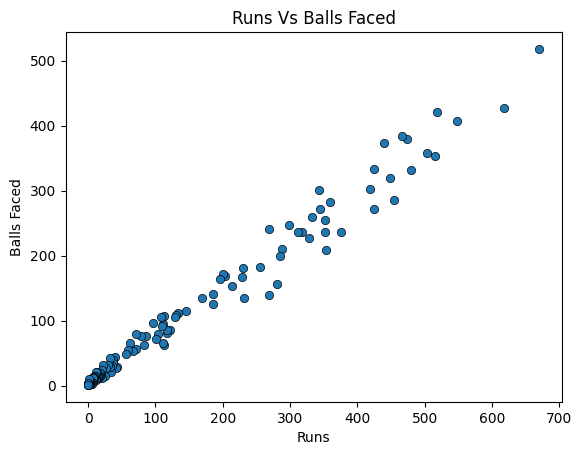

In [61]:
sns.scatterplot(x=df['Runs'],y=df['Balls faced'],edgecolor='black')

plt.title('Runs Vs Balls Faced')
plt.xlabel('Runs')
plt.ylabel('Balls Faced')
plt.show()

In [62]:
df[['Runs','Balls faced']].corr()

,Runs,Balls faced
Runs,1.000000,0.989948
Balls faced,0.989948,1.000000


In [63]:
# Correlation betwwen Runs and balls faced is 0.98